## Load the data

In [1]:
from pathlib import Path
import pandas as pd

directory = Path("../../data/cryptohftdata/derived/datasets/btcusdt_v2/time_1m-bf7241b5e9")
files = sorted(directory.glob("*.parquet"))

df = pd.concat(
    [pd.read_parquet(file) for file in files],
    ignore_index=True
).sort_values("bar_id").reset_index(drop=True)


In [2]:
df.shape

(707040, 664)

In [3]:
import numpy as np

def validate_bars(df, expected_duration_s=60):
    required = [
        "bar_id",
        "decision_time_ns",
        "eval_time_ns",
        "t_start_ns",
        "t_end_ns",
    ]

    assert all(c in df.columns for c in required), "Lipsesc coloane"
    assert len(df) > 0, "DataFrame gol"

    results = []

    def check(name, condition):
        condition = np.asarray(condition, dtype=bool)
        bad = np.flatnonzero(~condition)

        results.append({
            "check": name,
            "status": "PASS" if len(bad) == 0 else "FAIL",
            "errors": len(bad),
        })

        if len(bad):
            print(f"\n{name}: {len(bad):,} erori")
            print("Poziții problematice:", bad[:10])

    check(
        "No missing values",
        ~df[required].isna().any(axis=1).to_numpy()
    )

    ids = df["bar_id"].to_numpy()
    start = df["t_start_ns"].to_numpy()
    end = df["t_end_ns"].to_numpy()
    decision = df["decision_time_ns"].to_numpy()
    evaluation = df["eval_time_ns"].to_numpy()

    check("Unique bar_id", ~df["bar_id"].duplicated().to_numpy())
    check("bar_id ascending", np.r_[True, np.diff(ids) > 0])
    check("bar_id consecutive", np.r_[True, np.diff(ids) == 1])

    check("Start ascending", np.r_[True, np.diff(start) > 0])
    check("End ascending", np.r_[True, np.diff(end) > 0])
    check("Decision ascending", np.r_[True, np.diff(decision) > 0])

    check("Start < End", start < end)
    check("Start <= Evaluation", start <= evaluation)
    check("Evaluation < Decision", evaluation < decision)
    check("End <= Decision", end <= decision)

    check("No overlapping bars", np.r_[True, start[1:] >= end[:-1]])

    if expected_duration_s is not None:
        check(
            "Continuous bars",
            np.r_[True, start[1:] == end[:-1]]
        )
        check(
            "Correct bar duration",
            (end - start) == int(expected_duration_s * 1e9)
        )
        check("Decision == End", decision == end)
        check("Evaluation == Decision - 1 ns", evaluation == decision - 1)

    report = pd.DataFrame(results)

    print("\n=== VALIDATION REPORT ===")
    print(report.to_string(index=False))

    print(f"\nTotal rows: {len(df):,}")
    print(f"Total failed checks: {(report.status == 'FAIL').sum()}")

    return report


report = validate_bars(df)


=== VALIDATION REPORT ===
                        check status  errors
            No missing values   PASS       0
                Unique bar_id   PASS       0
             bar_id ascending   PASS       0
           bar_id consecutive   PASS       0
              Start ascending   PASS       0
                End ascending   PASS       0
           Decision ascending   PASS       0
                  Start < End   PASS       0
          Start <= Evaluation   PASS       0
        Evaluation < Decision   PASS       0
              End <= Decision   PASS       0
          No overlapping bars   PASS       0
              Continuous bars   PASS       0
         Correct bar duration   PASS       0
              Decision == End   PASS       0
Evaluation == Decision - 1 ns   PASS       0

Total rows: 707,040
Total failed checks: 0


In [4]:
df = df.set_index("bar_id", verify_integrity=True)
df = df.sort_index()

print(df.index.is_unique)
print(df.index.is_monotonic_increasing)

True
True


In [5]:
df.head()

,decision_time_ns,eval_time_ns,t_start_ns,t_end_ns,t_open_recv_ns,t_close_recv_ns,m_open_ms,m_close_ms,first_seq,last_seq,...,liq_long_to_bid_depth_10bps_15m,liq_to_trade_notional_1h,liq_to_oi_1h,liq_short_to_ask_depth_10bps_1h,liq_long_to_bid_depth_10bps_1h,activity_vs_ticker24h_2m,activity_vs_ticker24h_15m,activity_vs_ticker24h_1h,rv_ratio_2m_1h_grid1s,liq_any_2m_x_rv_ratio
bar_id,,,,,,,,,,,,,,,,,,,,,
0,1751068860000000000,1751068859999999999,1751068800000000000,1751068860000000000,0,0,0,0,-1,-1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1751068920000000000,1751068919999999999,1751068860000000000,1751068920000000000,0,0,0,0,-1,-1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1751068980000000000,1751068979999999999,1751068920000000000,1751068980000000000,0,0,0,0,-1,-1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1751069040000000000,1751069039999999999,1751068980000000000,1751069040000000000,0,0,0,0,-1,-1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1751069100000000000,1751069099999999999,1751069040000000000,1751069100000000000,0,0,0,0,-1,-1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
list(df.columns)

['decision_time_ns',
 'eval_time_ns',
 't_start_ns',
 't_end_ns',
 't_open_recv_ns',
 't_close_recv_ns',
 'm_open_ms',
 'm_close_ms',
 'first_seq',
 'last_seq',
 'first_trade_id',
 'last_trade_id',
 'seg',
 'close_reason',
 'complete',
 'threshold_int',
 'feed_complete',
 'bar_open',
 'bar_high',
 'bar_low',
 'bar_close',
 'bar_n_trades',
 'bar_volume_btc',
 'bar_notional_usdt',
 'bar_vwap',
 'bar_return_log',
 'bar_oc_log',
 'bar_range_log',
 'bar_close_location',
 'bar_tfi_btc',
 'bar_tfi_usdt',
 'bar_tfi_ratio',
 'bar_count_imbalance',
 'bar_mean_trade_size_btc',
 'bar_duration_s',
 'bar_volume_rate_btc_s',
 'bar_notional_rate_usdt_s',
 'last_trade_price',
 'last_trade_age_ms',
 'tw_state_5s',
 'tw_state_30s',
 'tw_state_2m',
 'tw_state_15m',
 'tw_state_1h',
 'tw_state_4h',
 'tw_state_24h',
 'trade_count_5s',
 'volume_5s_btc',
 'notional_5s_usdt',
 'trade_rate_5s_per_s',
 'volume_rate_5s_btc_s',
 'notional_rate_5s_usdt_s',
 'tfi_5s_btc',
 'tfi_5s_usdt',
 'tfi_ratio_5s',
 'count_imba

## Create the target

In [7]:
def create_forward_returns(
    df,
    horizons=(1, 2, 3, 5, 10, 20),
    require_feed_complete=False
):
    if "bar_id" in df.columns:
        df = df.set_index("bar_id", verify_integrity=True)
    elif df.index.name != "bar_id":
        raise ValueError("bar_id trebuie să fie coloană sau index.")

    df = df.sort_index()

    ids = df.index.to_numpy(dtype=np.int64)
    n = len(df)

    if n == 0 or np.any(np.diff(ids) <= 0):
        raise ValueError("bar_id invalid.")

    price = df["bar_close"].to_numpy(dtype=np.float64)
    valid_price = np.isfinite(price) & (price > 0)

    log_price = np.full(n, np.nan, dtype=np.float64)
    np.log(price, out=log_price, where=valid_price)

    invalid = ~valid_price

    if "complete" in df.columns:
        invalid |= ~df["complete"].fillna(False).astype(bool).to_numpy()

    if require_feed_complete and "feed_complete" in df.columns:
        invalid |= ~df["feed_complete"].fillna(False).astype(bool).to_numpy()

    breaks = np.zeros(n, dtype=bool)
    breaks[1:] = np.diff(ids) != 1

    if "seg" in df.columns:
        seg = df["seg"].to_numpy()
        breaks[1:] |= seg[1:] != seg[:-1]

    invalid_cumsum = np.cumsum(invalid, dtype=np.int64)
    breaks_cumsum = np.cumsum(breaks, dtype=np.int64)

    # 5. Generarea targeturilor
    targets = pd.DataFrame(index=df.index)

    for k in horizons:
        k = int(k)

        if k < 1:
            raise ValueError("Orizontul trebuie să fie >= 1.")

        y = np.full(n, np.nan, dtype=np.float32)

        if k < n:
            valid = (
                ~invalid[:-k]
                & (invalid_cumsum[k:] == invalid_cumsum[:-k])
                & (breaks_cumsum[k:] == breaks_cumsum[:-k])
            )

            future_return = log_price[k:] - log_price[:-k]

            y[:-k] = np.where(
                valid, future_return, np.nan
            ).astype(np.float32)

        targets[f"ret_{k}fw"] = y

    return df, targets


# Utilizare
df, targets = create_forward_returns(df)

# Adăugare în DataFrame
for col in targets.columns:
    df[col] = targets[col]

print(df[targets.columns].describe())
print(df[targets.columns].isna().mean() * 100)

            ret_1fw       ret_2fw       ret_3fw        ret_5fw       ret_10fw  \
count  7.044300e+05  7.026550e+05  7.009640e+05  697743.000000  690143.000000   
mean  -2.622069e-07 -5.893335e-07 -8.665116e-07      -0.000002      -0.000004   
std    5.802467e-04  8.120650e-04  9.879557e-04       0.001264       0.001755   
min   -1.482924e-02 -1.964105e-02 -2.061814e-02      -0.024157      -0.033267   
25%   -2.370863e-04 -3.372160e-04 -4.110754e-04      -0.000531      -0.000750   
50%    0.000000e+00  0.000000e+00  0.000000e+00      -0.000002      -0.000005   
75%    2.359381e-04  3.338674e-04  4.074139e-04       0.000524       0.000743   
max    3.209121e-02  3.842998e-02  3.802500e-02       0.042692       0.046183   

            ret_20fw  
count  676154.000000  
mean       -0.000006  
std         0.002438  
min        -0.046749  
25%        -0.001046  
50%         0.000000  
75%         0.001044  
max         0.051568  
ret_1fw     0.369145
ret_2fw     0.620191
ret_3fw     0.859357


## EDA

In [8]:
import re
import math
from IPython.display import display

HORIZONS = [1, 2, 3, 5, 10, 20]
TOP_N = 80


MAX_ROWS = 300_000

CHUNK_SIZE = 16
MIN_PAIRS = 1000

targets = [
    f"ret_{h}fw"
    for h in HORIZONS
    if f"ret_{h}fw" in df.columns
]

if not targets:
    raise ValueError("Nu există targeturi forward în df.")

exclude = {
    "bar_id",
    "decision_time_ns",
    "eval_time_ns",
    "t_start_ns",
    "t_end_ns",
    "t_open_recv_ns",
    "t_close_recv_ns",
    "m_open_ms",
    "m_close_ms",
    "first_seq",
    "last_seq",
    "first_trade_id",
    "last_trade_id",
    "seg",
    "close_reason",
    "threshold_int",
    "oi_reference_ts_ns",
    "complete",
    "feed_complete",
}

features = [
    c for c in df.select_dtypes(include=["number", "bool"]).columns
    if c not in exclude
    and not re.match(r"^ret_\d+fw$", c)
    and not re.match(r"^duration_\d+fw_s$", c)
]

if MAX_ROWS is not None and len(df) > MAX_ROWS:
    step = math.ceil(len(df) / MAX_ROWS)
    data = df.iloc[::step]
else:
    data = df

print(f"Observații analizate: {len(data):,}")
print(f"Features analizate: {len(features)}")
print(f"Targets: {targets}")

corr_table = pd.DataFrame(index=features, columns=targets, dtype=float)
n_table = pd.DataFrame(index=features, columns=targets, dtype=float)

for start in range(0, len(features), CHUNK_SIZE):
    cols = features[start:start + CHUNK_SIZE]

    X = data[cols].astype("float64")
    X = X.replace([np.inf, -np.inf], np.nan)

    for target in targets:
        y = pd.to_numeric(data[target], errors="coerce")
        y = y.replace([np.inf, -np.inf], np.nan)

        corr = X.corrwith(y, method="pearson")
        counts = X.notna().mul(y.notna(), axis=0).sum()

        corr_table.loc[cols, target] = corr
        n_table.loc[cols, target] = counts

corr_table = corr_table.mask(n_table < MIN_PAIRS)

top40_by_target = {}

for target in targets:
    top = (
        corr_table[target]
        .dropna()
        .sort_values(key=lambda x: x.abs(), ascending=False)
        .head(TOP_N)
        .to_frame(name="correlation")
    )

    top["abs_corr"] = top["correlation"].abs()
    top["n_pairs"] = n_table.loc[top.index, target].astype(int)
    top["coverage_pct"] = (
        top["n_pairs"] / data[target].notna().sum() * 100
    )

    top40_by_target[target] = top

    print(f"\n===== TOP {TOP_N}: {target} =====")
    display(top.round(5))


max_abs_corr = corr_table.abs().max(axis=1)

top40_features = (
    max_abs_corr
    .dropna()
    .nlargest(TOP_N)
    .index
    .tolist()
)

top40_global = corr_table.loc[top40_features].copy()
top40_global.insert(
    0, "max_abs_corr",
    max_abs_corr.loc[top40_features]
)

print("\n===== TOP 40 GLOBAL =====")
display(top40_global.round(5))

Observații analizate: 235,680
Features analizate: 645
Targets: ['ret_1fw', 'ret_2fw', 'ret_3fw', 'ret_5fw', 'ret_10fw', 'ret_20fw']


/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/numpy/lib/_function_base_imp


===== TOP 80: ret_1fw =====


,correlation,abs_corr,n_pairs,coverage_pct
qi_top10,0.07942,0.07942,228889,97.49292
qi_top5,0.07931,0.07931,228889,97.49292
qi_1,0.07886,0.07886,228889,97.49292
qi_top20,0.07863,0.07863,228889,97.49292
qi_1bps,0.07671,0.07671,228883,97.49036
...,...,...,...,...
depth_bid_top5_btc,0.01444,0.01444,228889,97.49292
settle_est_index_bps_p2,0.01437,0.01437,232895,99.19923
signed_large_flow_5s_usdt,-0.01429,0.01429,234350,99.81898
ret_mark_15m,-0.01428,0.01428,231470,98.59227



===== TOP 80: ret_2fw =====


,correlation,abs_corr,n_pairs,coverage_pct
qi_top5,0.05160,0.05160,228412,97.52403
qi_top10,0.05141,0.05141,228412,97.52403
qi_1,0.05109,0.05109,228412,97.52403
qi_top20,0.05057,0.05057,228412,97.52403
qi_1bps,0.04894,0.04894,228406,97.52147
...,...,...,...,...
rebound_from_low_2m,-0.01298,0.01298,233127,99.53717
pressure_buy_5bps_5s,-0.01288,0.01288,227900,97.30542
liq_notional_rate_15m_usdt_s,0.01282,0.01282,227786,97.25675
bv_trade_4h_grid1m,-0.01268,0.01268,157193,67.11598


... (6 outputs left out)


===== TOP 80: ret_20fw =====


,correlation,abs_corr,n_pairs,coverage_pct
pressure_net_5bps_15m,-0.04784,0.04784,194658,86.36727
liq_long_to_bid_depth_10bps_15m,0.03498,0.03498,213726,94.82749
rv_neg_trade_15m_grid1s,0.03068,0.03068,218943,97.14221
tw_spread_bps_15m,0.02998,0.02998,196698,87.27239
liq_long_to_bid_depth_10bps_1h,0.02996,0.02996,202102,89.67007
...,...,...,...,...
qi_1,0.01481,0.01481,220107,97.65866
notional_15m_vs_slot_median_28d,0.01477,0.01477,215346,95.54627
bar_oc_log,-0.01469,0.01469,225384,100.00000
eff_spread_dw_bps_15m,-0.01462,0.01462,196211,87.05631



===== TOP 40 GLOBAL =====


,max_abs_corr,ret_1fw,ret_2fw,ret_3fw,ret_5fw,ret_10fw,ret_20fw
qi_top10,0.07942,0.07942,0.05141,0.04206,0.03218,0.02350,0.01510
qi_top5,0.07931,0.07931,0.05160,0.04234,0.03217,0.02348,0.01491
qi_1,0.07886,0.07886,0.05109,0.04180,0.03137,0.02330,0.01481
qi_top20,0.07863,0.07863,0.05057,0.04170,0.03170,0.02321,0.01452
qi_1bps,0.07671,0.07671,0.04894,0.03953,0.02949,0.02113,0.01004
...,...,...,...,...,...,...,...
rv_neg_trade_5s_grid100ms,0.02014,0.02014,0.01685,0.01213,0.00634,0.00724,0.00857
pressure_net_5bps_2m,0.02012,-0.00848,-0.00892,-0.01497,-0.01254,-0.01029,-0.02012
liq_to_oi_15m,0.01997,0.00365,0.01333,0.01252,0.01520,0.01516,0.01997
pressure_buy_5bps_5s,0.01991,-0.01991,-0.01288,-0.01078,-0.01142,-0.01803,-0.01356


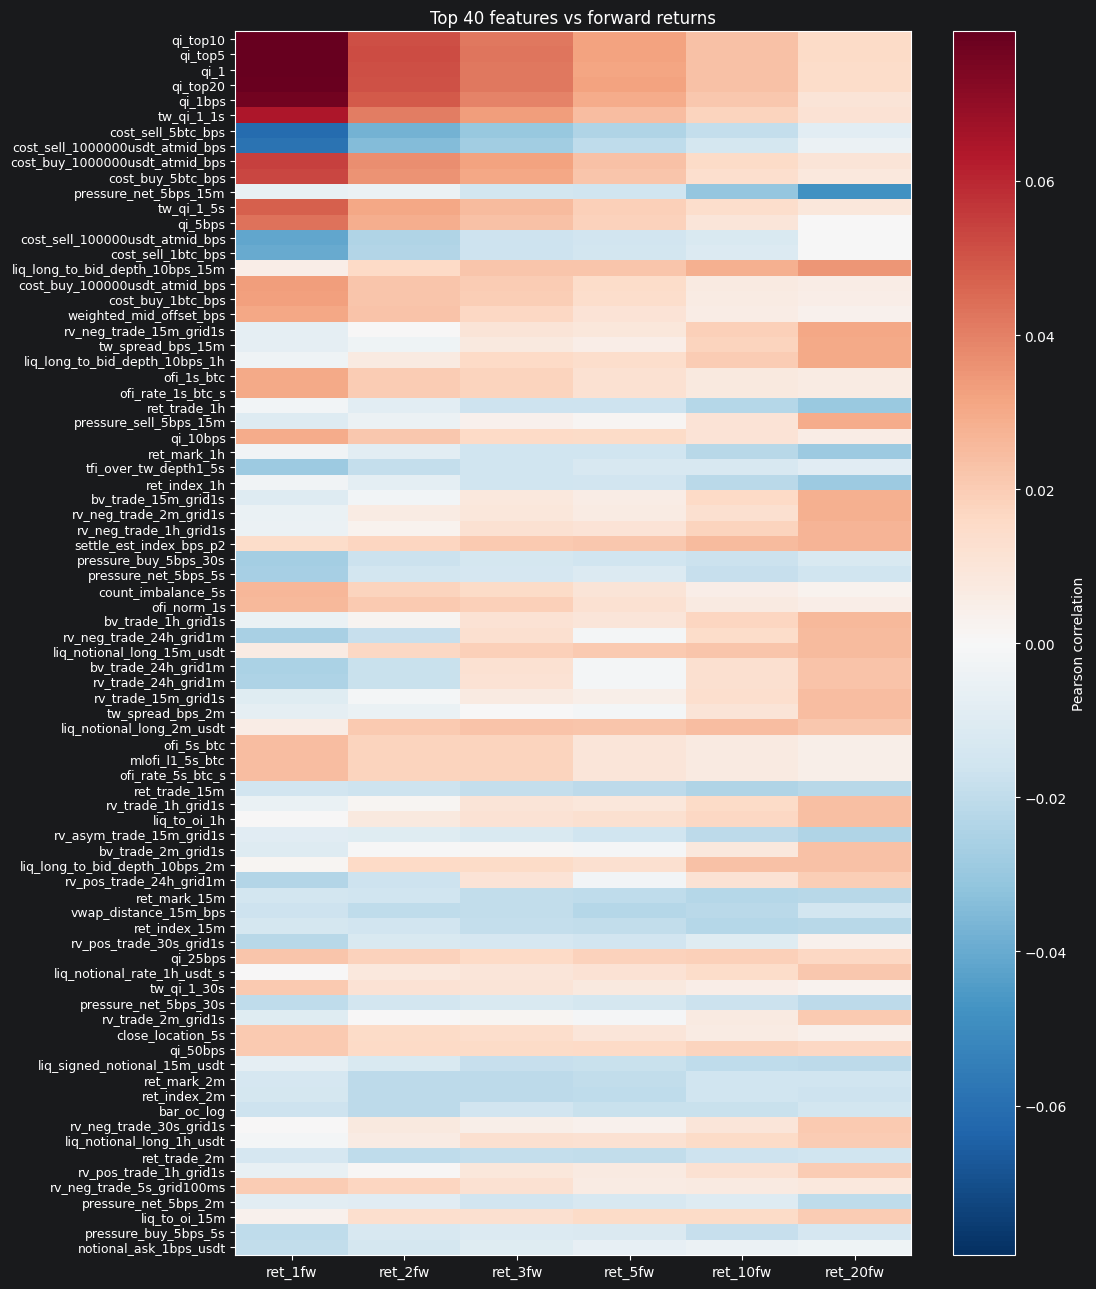

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 13))

matrix = top40_global[targets]

plt.imshow(
    matrix,
    aspect="auto",
    cmap="RdBu_r",
    vmin=-matrix.abs().max().max(),
    vmax=matrix.abs().max().max()
)

plt.yticks(
    range(len(matrix)),
    matrix.index,
    fontsize=9
)

plt.xticks(
    range(len(targets)),
    targets
)

plt.colorbar(label="Pearson correlation")
plt.title("Top 40 features vs forward returns")
plt.tight_layout()
plt.show()

,ret_1fw,ret_2fw,ret_3fw,ret_5fw,ret_10fw,ret_20fw
decile,,,,,,
0.0,-0.825,-0.790,-0.784,-0.820,-0.866,-0.819
1.0,-0.553,-0.472,-0.479,-0.465,-0.469,-0.542
2.0,-0.339,-0.296,-0.270,-0.268,-0.340,-0.284
3.0,-0.182,-0.179,-0.214,-0.190,-0.176,-0.255
4.0,-0.005,-0.031,-0.007,0.025,-0.031,-0.132
5.0,0.070,0.056,0.061,0.043,0.056,0.014
6.0,0.208,0.212,0.240,0.262,0.196,0.250
7.0,0.317,0.284,0.247,0.254,0.288,0.226
8.0,0.512,0.422,0.392,0.302,0.300,0.271


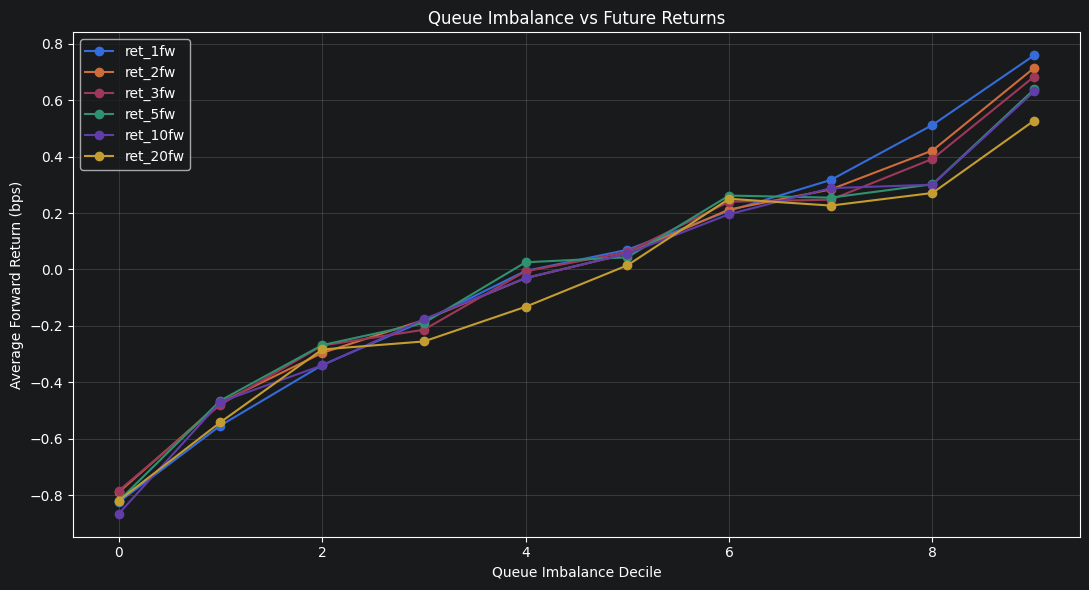

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

feature = "qi_top10"
targets = ["ret_1fw", "ret_2fw", "ret_3fw",
           "ret_5fw", "ret_10fw", "ret_20fw"]

data = df[[feature] + targets].copy()

data["decile"] = pd.qcut(
    data[feature],
    q=10,
    labels=False,
    duplicates="drop"
)

# Randamente medii în basis points
result = (
    data.groupby("decile")[targets]
    .mean()
    .mul(10000)
)

display(result.round(3))

result.plot(
    figsize=(11, 6),
    marker="o"
)

plt.xlabel("Queue Imbalance Decile")
plt.ylabel("Average Forward Return (bps)")
plt.title("Queue Imbalance vs Future Returns")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
feature = "qi_top10"
horizons = [1, 2, 3, 5, 10, 20]
targets = [f"ret_{h}fw" for h in horizons]

data = df.sort_values("decision_time_ns").copy()

split = int(len(data) * 0.8)

train = data.iloc[:split - max(horizons)].copy()
test = data.iloc[split:].copy()

_, bins = pd.qcut(
    train[feature].dropna(),
    q=10,
    retbins=True,
    duplicates="drop"
)

bins[0] = -np.inf
bins[-1] = np.inf

test["decile"] = pd.cut(
    test[feature],
    bins=bins,
    labels=False,
    include_lowest=True
)

result = (
    test.groupby("decile")[targets]
    .mean()
    .mul(10_000)
)

print("OUT-OF-SAMPLE DECILE RETURNS")
display(result.round(4))

low, high = result.index.min(), result.index.max()

spread = result.loc[high] - result.loc[low]

print("\nSPREAD EXTREME DECILES (bps)")
display(spread.round(4))

OUT-OF-SAMPLE DECILE RETURNS


,ret_1fw,ret_2fw,ret_3fw,ret_5fw,ret_10fw,ret_20fw
decile,,,,,,
0.0,-0.7859,-0.6136,-0.5722,-0.6114,-0.3902,-0.2636
1.0,-0.5330,-0.4468,-0.5105,-0.5517,-0.5937,-0.4209
2.0,-0.3533,-0.3341,-0.3548,-0.3055,-0.2314,-0.1857
3.0,-0.1611,-0.1408,-0.0874,-0.0316,0.1368,0.1791
4.0,-0.0353,-0.0952,-0.0763,-0.0536,0.0331,0.1425
5.0,0.1340,0.1257,0.1685,0.1386,0.2198,0.3205
6.0,0.2355,0.2911,0.3500,0.3979,0.3768,0.5228
7.0,0.2923,0.2907,0.2827,0.3695,0.2432,0.3348
8.0,0.4602,0.4100,0.4096,0.3936,0.3896,0.3930



SPREAD EXTREME DECILES (bps)


ret_1fw     1.5727
ret_2fw     1.3211
ret_3fw     1.2337
ret_5fw     1.3304
ret_10fw    1.1427
ret_20fw    0.9400
dtype: float32

## LightGBM

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

TARGET = "ret_5fw"
HORIZON = 1

# Economically motivated feature selection
features = [
    # Order book imbalance
    "qi_top10",
    "tw_qi_1_5s",
    "weighted_mid_offset_bps",

    # Order flow imbalance
    "ofi_norm_5s",
    "ofi_norm_30s",

    # Trade flow
    "bar_tfi_ratio",
    "tfi_ratio_5s",
    "tfi_ratio_30s",
    "count_imbalance_5s",

    # Liquidity and spread
    "spread_bps",
    "pressure_net_5bps_5s",

    # Price action
    "bar_return_log",
    "ret_trade_30s",
    "ret_trade_2m",

    # Volatility
    "rv_trade_30s_grid1s",
    "rv_trade_2m_grid1s",

    # Market activity
    "bar_duration_s",
    "notional_rate_ratio_5s_vs_24h",

    # Derivatives
    "oi_log_change_known_15m",
    "liq_imbalance_2m",
    "basis_mid_index_bps",

    # Time features
    "hour_of_day_sin",
    "hour_of_day_cos",
]

# Keep only available features
features = [f for f in features if f in df.columns]

# Chronological ordering
data = df.sort_values("decision_time_ns", kind="stable")

# Chronological train/validation/test split
n = len(data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

if train_end <= HORIZON or val_end - train_end <= HORIZON:
    raise ValueError("Not enough observations for purged splits.")

# Purge observations whose forward target crosses a split boundary
train = data.iloc[:train_end - HORIZON]
val = data.iloc[train_end:val_end - HORIZON]
test = data.iloc[val_end:]

def prepare_split(split, selected_features):
    # Remove only rows with missing targets
    split = split.loc[split[TARGET].notna()]

    X = (
        split[selected_features]
        .replace([np.inf, -np.inf], np.nan)
        .astype("float64")
    )

    # Convert log returns to basis points
    y = split[TARGET].astype("float64") * 10_000

    return X, y

X_train, y_train = prepare_split(train, features)
X_val, y_val = prepare_split(val, features)
X_test, y_test = prepare_split(test, features)

# Remove empty or constant features using train data only
usable = (
    X_train.notna().any()
    & (X_train.nunique(dropna=True) > 1)
)

features = usable[usable].index.tolist()

X_train = X_train[features]
X_val = X_val[features]
X_test = X_test[features]

# All preprocessing steps are fitted exclusively on training data
model = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)

# Predictions
pred_train = model.predict(X_train)
pred_val = model.predict(X_val)
pred_test = model.predict(X_test)

print(f"Train: {len(X_train):,}")
print(f"Validation: {len(X_val):,}")
print(f"Test: {len(X_test):,}")
print(f"Features: {len(features)}")

Train: 487,118
Validation: 105,163
Test: 105,460
Features: 22


In [13]:
def evaluate_regression(y_true, y_pred, baseline_mean):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    baseline_pred = np.full_like(
        y_true, baseline_mean, dtype=float
    )

    ic = (
        np.corrcoef(y_true, y_pred)[0, 1]
        if np.std(y_pred) > 0 and np.std(y_true) > 0
        else np.nan
    )

    baseline_mse = mean_squared_error(
        y_true, baseline_pred
    )
    model_mse = mean_squared_error(y_true, y_pred)

    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE_bps": np.sqrt(model_mse),
        "MAE_bps": mean_absolute_error(y_true, y_pred),
        "Pearson_IC": ic,
        "Direction_Acc": np.mean(
            np.sign(y_true) == np.sign(y_pred)
        ),
        "Baseline_RMSE_bps": np.sqrt(baseline_mse),
        "MSE_Improvement_%": (
            (1 - model_mse / baseline_mse) * 100
            if baseline_mse > 0 else np.nan
        )
    }


# The baseline is fixed using train data only
baseline_mean = y_train.mean()

results = pd.DataFrame({
    "Train": evaluate_regression(
        y_train, pred_train, baseline_mean
    ),
    "Validation": evaluate_regression(
        y_val, pred_val, baseline_mean
    ),
    "Test": evaluate_regression(
        y_test, pred_test, baseline_mean
    )
}).T

display(results.round(5))

,R2,RMSE_bps,MAE_bps,Pearson_IC,Direction_Acc,Baseline_RMSE_bps,MSE_Improvement_%
Train,0.00193,13.17298,8.50165,0.04399,0.52304,13.18574,0.19349
Validation,0.00173,10.99444,7.09693,0.04259,0.52165,11.00405,0.17461
Test,0.00061,11.51575,7.46698,0.03226,0.51807,11.51993,0.07251


,mean_prediction_bps,mean_actual_bps,count
pred_decile,,,
0,-0.9548,-0.2743,10492
1,-0.5979,-0.3961,9169
2,-0.4302,-0.3015,9638
3,-0.2827,-0.1480,10062
4,-0.1399,0.0034,10666
5,-0.0014,0.1055,10721
6,0.1371,0.1776,10357
7,0.2808,0.2836,10185
8,0.4542,0.2719,10441


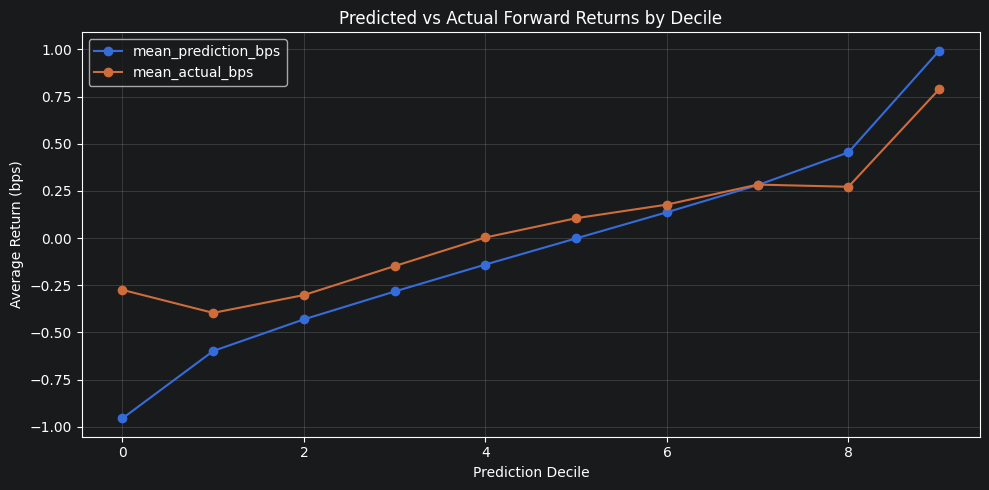

In [14]:
# Inspect the prediction distribution on the test set
predictions = pd.DataFrame({
    "actual_bps": y_test.to_numpy(),
    "predicted_bps": pred_test
}, index=X_test.index)

# Decile thresholds are fitted on validation predictions
_, bins = pd.qcut(
    pred_val,
    q=10,
    retbins=True,
    duplicates="drop"
)

bins[0] = -np.inf
bins[-1] = np.inf

predictions["pred_decile"] = pd.cut(
    predictions["predicted_bps"],
    bins=bins,
    labels=False,
    include_lowest=True
)

decile_results = (
    predictions.groupby("pred_decile")
    .agg(
        mean_prediction_bps=("predicted_bps", "mean"),
        mean_actual_bps=("actual_bps", "mean"),
        count=("actual_bps", "size")
    )
)

display(decile_results.round(4))

decile_results[
    ["mean_prediction_bps", "mean_actual_bps"]
].plot(
    figsize=(10, 5),
    marker="o",
    title="Predicted vs Actual Forward Returns by Decile"
)

plt.xlabel("Prediction Decile")
plt.ylabel("Average Return (bps)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## LightGBM

In [15]:
import lightgbm as lgb

# Prepare the same datasets used for Linear Regression
X_train_lgb = X_train.replace([np.inf, -np.inf], np.nan)
X_val_lgb = X_val.replace([np.inf, -np.inf], np.nan)
X_test_lgb = X_test.replace([np.inf, -np.inf], np.nan)

# Conservative configuration to reduce overfitting on noisy returns
lgb_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=5,
    min_child_samples=500,
    colsample_bytree=0.85,
    reg_alpha=1.0,
    reg_lambda=10.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Train with early stopping based only on validation performance
lgb_model.fit(
    X_train_lgb,
    y_train,
    eval_set=[(X_val_lgb, y_val)],
    eval_metric="l2",
    callbacks=[
        lgb.early_stopping(100, verbose=False),
        lgb.log_evaluation(100)
    ]
)

# Generate predictions without modifying Linear Regression results
pred_lgb_train = lgb_model.predict(X_train_lgb)
pred_lgb_val = lgb_model.predict(X_val_lgb)
pred_lgb_test = lgb_model.predict(X_test_lgb)

print(f"Best iteration: {lgb_model.best_iteration_}")
print(f"Features: {X_train_lgb.shape[1]}")

[100]	valid_0's l2: 120.977
Best iteration: 38
Features: 22


In [16]:
# Evaluate LightGBM using the same metrics and baseline
lgb_results = pd.DataFrame({
    "Train": evaluate_regression(
        y_train, pred_lgb_train, baseline_mean
    ),
    "Validation": evaluate_regression(
        y_val, pred_lgb_val, baseline_mean
    ),
    "Test": evaluate_regression(
        y_test, pred_lgb_test, baseline_mean
    )
}).T

print("=== LightGBM Results ===")
display(lgb_results.round(5))

# Compare against the existing Linear Regression results
comparison = pd.concat(
    {
        "Linear Regression": results,
        "LightGBM": lgb_results
    },
    names=["Model", "Split"]
)

print("=== Model Comparison ===")
display(comparison.round(5))

=== LightGBM Results ===


,R2,RMSE_bps,MAE_bps,Pearson_IC,Direction_Acc,Baseline_RMSE_bps,MSE_Improvement_%
Train,0.00335,13.16366,8.50289,0.07627,0.52350,13.18574,0.33469
Validation,0.00130,10.99681,7.09980,0.03678,0.51949,11.00405,0.13159
Test,0.00120,11.51232,7.46575,0.03864,0.51975,11.51993,0.13212


=== Model Comparison ===


R2  RMSE_bps  MAE_bps  Pearson_IC  \
Model             Split                                                
Linear Regression Train       0.00193  13.17298  8.50165     0.04399   
                  Validation  0.00173  10.99444  7.09693     0.04259   
                  Test        0.00061  11.51575  7.46698     0.03226   
LightGBM          Train       0.00335  13.16366  8.50289     0.07627   
                  Validation  0.00130  10.99681  7.09980     0.03678   
                  Test        0.00120  11.51232  7.46575     0.03864   

                              Direction_Acc  Baseline_RMSE_bps  \
Model             Split                                          
Linear Regression Train             0.52304           13.18574   
                  Validation        0.52165           11.00405   
                  Test              0.51807           11.51993   
LightGBM          Train             0.52350           13.18574   
                  Validation        0.51949           11.00405   
                  Test              0.51975           11.51993   

                              MSE_Improvement_%  
Model             Split                          
Linear Regression Train                 0.19349  
                  Validation            0.17461  
                  Test                  0.07251  
LightGBM          Train                 0.33469  
                  Validation            0.13159  
                  Test                  0.13212

,feature,importance,importance_pct
0,qi_top10,794540.731,16.572
15,rv_trade_2m_grid1s,662067.891,13.809
2,weighted_mid_offset_bps,490822.778,10.237
13,ret_trade_2m,424874.211,8.862
9,spread_bps,406394.299,8.476
14,rv_trade_30s_grid1s,276203.462,5.761
20,hour_of_day_sin,269672.959,5.625
18,liq_imbalance_2m,244146.910,5.092
7,tfi_ratio_30s,215301.182,4.491
17,oi_log_change_known_15m,191596.360,3.996


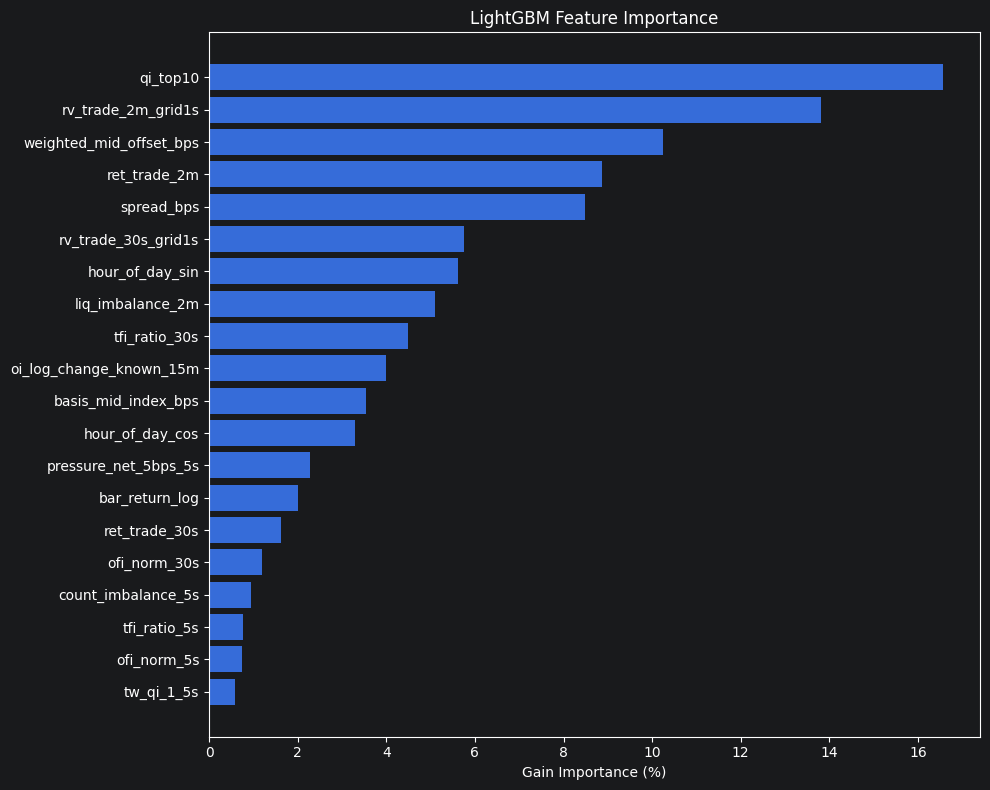

In [17]:
# Extract gain-based feature importance
importance = pd.DataFrame({
    "feature": X_train_lgb.columns,
    "importance": lgb_model.booster_.feature_importance(
        importance_type="gain"
    )
})

importance = importance.sort_values(
    "importance", ascending=False
)

importance["importance_pct"] = (
    importance["importance"]
    / importance["importance"].sum()
    * 100
)

display(importance.head(20).round(3))

# Plot the 20 most important features
top = importance.head(20).iloc[::-1]

plt.figure(figsize=(10, 8))
plt.barh(top["feature"], top["importance_pct"])
plt.xlabel("Gain Importance (%)")
plt.title("LightGBM Feature Importance")
plt.tight_layout()
plt.show()

## LightGBM with all the features

In [18]:
# Columns excluded from model inputs
metadata_cols = {
    "bar_id", "decision_time_ns", "eval_time_ns",
    "t_start_ns", "t_end_ns",
    "t_open_recv_ns", "t_close_recv_ns",
    "m_open_ms", "m_close_ms",
    "first_seq", "last_seq",
    "first_trade_id", "last_trade_id",
    "seg", "close_reason", "threshold_int",
    "complete", "feed_complete",
    "oi_reference_ts_ns"
}

# Exclude absolute price levels; keep returns, ratios and spreads
price_level_cols = {
    "bar_open", "bar_high", "bar_low", "bar_close",
    "bar_vwap", "last_trade_price",
    "best_bid", "best_ask", "mid",
    "mark_price", "index_price",
    "vwap_5s", "vwap_30s", "vwap_2m",
    "vwap_15m", "vwap_1h",
    "oi_value_price_implied"
}

# Select numerical features without using target correlations
all_features = [
    c for c in df.select_dtypes(include=["number", "bool"]).columns
    if c not in metadata_cols
    and c not in price_level_cols
    and not (c.startswith("ret_") and c.endswith("fw"))
    and not (c.startswith("duration_") and "fw" in c)
    and not c.startswith("markout_")
    and not c.startswith(("future_", "target_", "label_"))
    and c != "settle_est_index_bps_p2"
]

def prepare_full_X(split, index):
    return (
        split.loc[index, all_features]
        .replace([np.inf, -np.inf], np.nan)
        .astype("float32")
    )

X_train_full = prepare_full_X(train, X_train.index)
X_val_full = prepare_full_X(val, X_val.index)
X_test_full = prepare_full_X(test, X_test.index)

# Filter constant or almost entirely unavailable features on train only
min_coverage = 0.05

valid_features = (
    (X_train_full.notna().mean() >= min_coverage)
    & (X_train_full.nunique(dropna=True) > 1)
)

selected_features = valid_features[valid_features].index.tolist()

X_train_full = X_train_full[selected_features]
X_val_full = X_val_full[selected_features]
X_test_full = X_test_full[selected_features]

print(f"Selected features: {len(selected_features)}")
print(f"Train: {len(X_train_full):,}")
print(f"Validation: {len(X_val_full):,}")
print(f"Test: {len(X_test_full):,}")

# Train LightGBM with additional regularization
lgb_full = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=5,
    min_child_samples=1000,
    colsample_bytree=0.75,
    subsample=0.8,
    subsample_freq=1,
    reg_alpha=2.0,
    reg_lambda=20.0,
    max_bin=127,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_full.fit(
    X_train_full,
    y_train,
    eval_set=[(X_val_full, y_val)],
    eval_metric="l2",
    callbacks=[
        lgb.early_stopping(100, verbose=False),
        lgb.log_evaluation(100)
    ]
)

pred_full_train = lgb_full.predict(X_train_full)
pred_full_val = lgb_full.predict(X_val_full)
pred_full_test = lgb_full.predict(X_test_full)

full_results = pd.DataFrame({
    "Train": evaluate_regression(
        y_train, pred_full_train, baseline_mean
    ),
    "Validation": evaluate_regression(
        y_val, pred_full_val, baseline_mean
    ),
    "Test": evaluate_regression(
        y_test, pred_full_test, baseline_mean
    )
}).T

display(full_results.round(5))

# Compare the existing models against the full-feature model
comparison = pd.concat({
    "Linear Regression": results,
    "LightGBM Small": lgb_results,
    "LightGBM Full": full_results
})

display(comparison.round(5))

Selected features: 604
Train: 487,118
Validation: 105,163
Test: 105,460
[100]	valid_0's l2: 120.958
[200]	valid_0's l2: 121.068


,R2,RMSE_bps,MAE_bps,Pearson_IC,Direction_Acc,Baseline_RMSE_bps,MSE_Improvement_%
Train,0.02016,13.05213,8.45916,0.21035,0.53606,13.18574,2.01631
Validation,0.00130,10.99680,7.09901,0.03920,0.52041,11.00405,0.13174
Test,-0.00139,11.52722,7.46839,0.01303,0.51777,11.51993,-0.12664


R2  RMSE_bps  MAE_bps  Pearson_IC  \
Linear Regression Train       0.00193  13.17298  8.50165     0.04399   
                  Validation  0.00173  10.99444  7.09693     0.04259   
                  Test        0.00061  11.51575  7.46698     0.03226   
LightGBM Small    Train       0.00335  13.16366  8.50289     0.07627   
                  Validation  0.00130  10.99681  7.09980     0.03678   
                  Test        0.00120  11.51232  7.46575     0.03864   
LightGBM Full     Train       0.02016  13.05213  8.45916     0.21035   
                  Validation  0.00130  10.99680  7.09901     0.03920   
                  Test       -0.00139  11.52722  7.46839     0.01303   

                              Direction_Acc  Baseline_RMSE_bps  \
Linear Regression Train             0.52304           13.18574   
                  Validation        0.52165           11.00405   
                  Test              0.51807           11.51993   
LightGBM Small    Train             0.52350           13.18574   
                  Validation        0.51949           11.00405   
                  Test              0.51975           11.51993   
LightGBM Full     Train             0.53606           13.18574   
                  Validation        0.52041           11.00405   
                  Test              0.51777           11.51993   

                              MSE_Improvement_%  
Linear Regression Train                 0.19349  
                  Validation            0.17461  
                  Test                  0.07251  
LightGBM Small    Train                 0.33469  
                  Validation            0.13159  
                  Test                  0.13212  
LightGBM Full     Train                 2.01631  
                  Validation            0.13174  
                  Test                 -0.12664

,feature,gain,gain_pct
242,funding_change_1h,651585.8037,2.5360
186,jump_trade_4h_grid1m,598068.7676,2.3277
330,ticker_vwap_distance_trade_bps,594992.1582,2.3158
169,jump_trade_15m_grid1s,564378.3691,2.1966
225,tw_basis_mark_index_bps_1h,549575.9087,2.1390
161,bv_trade_2m_grid1s,423596.3916,1.6487
521,book_level_changes_15m,418725.0791,1.6297
338,day_of_week_cos,393559.7368,1.5318
318,liq_peak_1s_1h_usdt,361117.3984,1.4055
311,liq_count_1h,348533.1299,1.3565


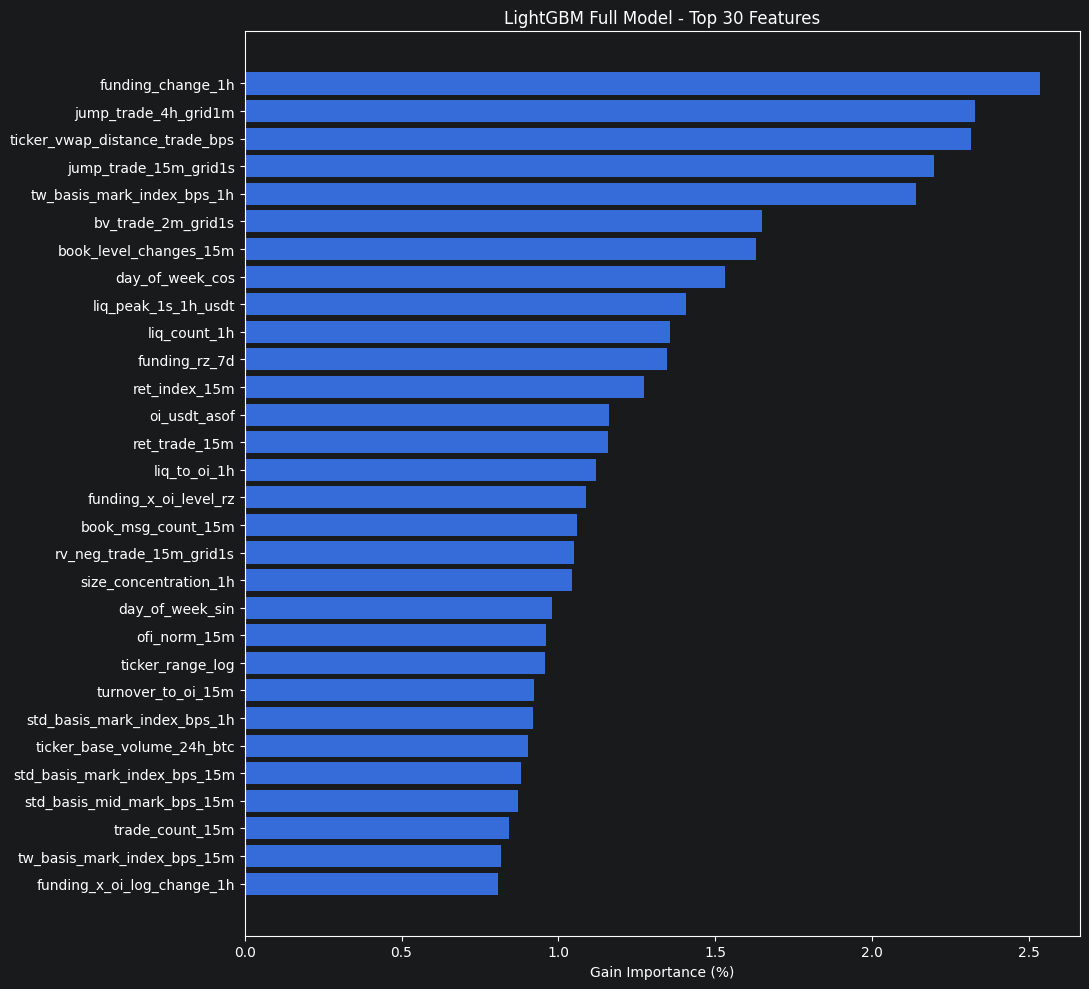

In [19]:
importance_full = pd.DataFrame({
    "feature": selected_features,
    "gain": lgb_full.booster_.feature_importance(
        importance_type="gain"
    )
})

importance_full["gain_pct"] = (
    importance_full["gain"]
    / importance_full["gain"].sum()
    * 100
)

importance_full = importance_full.sort_values(
    "gain", ascending=False
)

display(importance_full.head(50).round(4))

# Plot the 30 most important features
top = importance_full.head(30).iloc[::-1]

plt.figure(figsize=(11, 10))
plt.barh(top["feature"], top["gain_pct"])
plt.xlabel("Gain Importance (%)")
plt.title("LightGBM Full Model - Top 30 Features")
plt.tight_layout()
plt.show()

## Lag Features

In [20]:
TARGET = "ret_1fw"
HORIZON = 1
LAGS = [1, 2, 3, 5, 10]

# Use "time" for time bars and "volume" for volume bars
BAR_TYPE = "time"

# Features whose historical evolution may contain predictive information
lag_features = [
    # Order book imbalance
    "qi_top10",
    "qi_1",
    "weighted_mid_offset_bps",
    "tw_qi_1_5s",

    # Order flow
    "ofi_norm_5s",
    "ofi_norm_30s",
    "ofi_norm_2m",

    # Trade flow
    "tfi_ratio_5s",
    "tfi_ratio_30s",
    "bar_tfi_ratio",
    "run_sign",

    # Price dynamics
    "bar_return_log",
    "ret_trade_30s",
    "ret_trade_2m",

    # Liquidity
    "spread_bps",
    "pressure_net_5bps_5s",
    "depth_bid_5bps_btc",
    "depth_ask_5bps_btc",

    # Volatility
    "rv_trade_30s_grid1s",
    "rv_trade_2m_grid1s",

    # Market activity
    "bar_duration_s",
    "notional_rate_ratio_5s_vs_24h",

    # Derivatives
    "basis_mid_index_bps",
    "oi_log_change_known_15m",
    "liq_imbalance_2m",
]

# Sort observations chronologically
data = df.sort_values("decision_time_ns", kind="stable").copy()

if not data.index.is_unique:
    raise ValueError("DataFrame index must be unique.")

# Reuse the feature universe from the previous full LightGBM experiment
base_features = [
    c for c in dict.fromkeys(all_features)
    if c in data.columns
    and pd.api.types.is_numeric_dtype(data[c])
    and c != TARGET
    and not (c.startswith("ret_") and c.endswith("fw"))
    and not (c.startswith("duration_") and "fw" in c)
    and not c.startswith("markout_")
    and not c.startswith(("future_", "target_", "label_"))
]

lag_features = [c for c in lag_features if c in base_features]

# Check chronological continuity
if "bar_id" in data.columns:
    ids = data["bar_id"].to_numpy(dtype=np.int64)
elif data.index.name == "bar_id":
    ids = data.index.to_numpy(dtype=np.int64)
else:
    raise ValueError("bar_id must be a column or the DataFrame index.")

n = len(data)

breaks = np.zeros(n, dtype=bool)
breaks[1:] = ids[1:] != ids[:-1] + 1

# Prevent lag features from crossing dataset segments
if "seg" in data.columns:
    seg = data["seg"].to_numpy()
    breaks[1:] |= seg[1:] != seg[:-1]

# Time bars must be temporally contiguous
if BAR_TYPE == "time":
    starts = data["t_start_ns"].to_numpy()
    ends = data["t_end_ns"].to_numpy()
    breaks[1:] |= starts[1:] != ends[:-1]

segment_id = np.cumsum(breaks)

# Generate historical features
lag_columns = {}

for feature in lag_features:
    values = data[feature].to_numpy(dtype=np.float32)

    for lag in LAGS:
        shifted = np.full(n, np.nan, dtype=np.float32)

        # A historical feature is valid only within the same segment
        valid = segment_id[lag:] == segment_id[:-lag]

        shifted[lag:] = np.where(
            valid,
            values[:-lag],
            np.nan
        )

        lag_columns[f"{feature}_lag{lag}"] = shifted

lag_df = pd.DataFrame(lag_columns, index=data.index)

print(f"Base features: {len(base_features)}")
print(f"Historical features: {len(lag_features)}")
print(f"New lag features: {lag_df.shape[1]}")
print(f"Total candidate features: {len(base_features) + lag_df.shape[1]}")

Base features: 615
Historical features: 25
New lag features: 125
Total candidate features: 740


In [21]:
# Chronological split
train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Purge observations whose targets overlap the following split
train_stop = train_end - HORIZON
val_stop = val_end - HORIZON

if train_stop <= 0 or val_stop <= train_end:
    raise ValueError("Insufficient observations for purged splits.")

# Remove constant and low-coverage features based on training data only
train_base = (
    data.iloc[:train_stop][base_features]
    .replace([np.inf, -np.inf], np.nan)
)

valid_features = (
    (train_base.notna().mean() >= 0.05)
    & (train_base.nunique(dropna=True) > 1)
)

base_features = valid_features[valid_features].index.tolist()

def prepare_dataset(start, stop):
    subset = data.iloc[start:stop]

    # Keep observations with valid regression targets
    mask = (
        subset[TARGET].notna()
        & np.isfinite(subset[TARGET])
    )

    subset = subset.loc[mask]

    X_base = (
        subset[base_features]
        .replace([np.inf, -np.inf], np.nan)
        .astype("float32")
    )

    X_lags = (
        lag_df.loc[subset.index]
        .replace([np.inf, -np.inf], np.nan)
    )

    X_augmented = pd.concat([X_base, X_lags], axis=1)

    # Convert log returns to basis points
    y = subset[TARGET].to_numpy(dtype=np.float64) * 10_000

    return X_base, X_augmented, y


Xtr_base, Xtr_lag, ytr = prepare_dataset(0, train_stop)
Xva_base, Xva_lag, yva = prepare_dataset(train_end, val_stop)
Xte_base, Xte_lag, yte = prepare_dataset(val_end, n)

print("Dataset sizes:")
print(f"Train: {len(ytr):,}")
print(f"Validation: {len(yva):,}")
print(f"Test: {len(yte):,}")

print(f"\nBaseline features: {Xtr_base.shape[1]}")
print(f"Augmented features: {Xtr_lag.shape[1]}")

KeyboardInterrupt: 

In [ ]:
params = dict(
    objective="regression",
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=5,
    min_child_samples=1000,
    colsample_bytree=0.75,
    subsample=0.8,
    subsample_freq=1,
    reg_alpha=2.0,
    reg_lambda=20.0,
    max_bin=127,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

def train_lgb(X_train, y_train, X_val, y_val):
    model = lgb.LGBMRegressor(**params)

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        eval_metric="l2",
        callbacks=[
            lgb.early_stopping(100, verbose=False)
        ]
    )

    return model


# Model A: Current features only
model_base = train_lgb(
    Xtr_base, ytr,
    Xva_base, yva
)

# Model B: Current features + historical lags
model_lag = train_lgb(
    Xtr_lag, ytr,
    Xva_lag, yva
)

print(f"Baseline best iteration: {model_base.best_iteration_}")
print(f"Lag model best iteration: {model_lag.best_iteration_}")

In [ ]:
baseline_mean = ytr.mean()

def evaluate_model(model, datasets):
    rows = {}

    for split_name, (X, y) in datasets.items():
        prediction = model.predict(X)

        rows[split_name] = evaluate_regression(
            y, prediction, baseline_mean
        )

    return pd.DataFrame(rows).T


base_results = evaluate_model(
    model_base,
    {
        "Train": (Xtr_base, ytr),
        "Validation": (Xva_base, yva),
        "Test": (Xte_base, yte)
    }
)

lag_results = evaluate_model(
    model_lag,
    {
        "Train": (Xtr_lag, ytr),
        "Validation": (Xva_lag, yva),
        "Test": (Xte_lag, yte)
    }
)

comparison = pd.concat(
    {
        "Baseline": base_results,
        "With Lags": lag_results
    },
    names=["Model", "Split"]
)

display(comparison.round(5))

# Calculate improvements on validation and test
for split in ["Validation", "Test"]:
    print(f"\n=== {split.upper()} IMPROVEMENT ===")

    for metric in ["R2", "Pearson_IC", "Direction_Acc"]:
        improvement = (
            lag_results.loc[split, metric]
            - base_results.loc[split, metric]
        )

        print(f"{metric}: {improvement:+.6f}")